# 1. Dataset Curation

Downloads the two public source datasets and builds the `train/val/test/{class}/`
folder layout used by every later notebook.

- **FETAL_PLANES_DB** (Spain), Burgos-Artizzu et al. 2020, [Zenodo 3904280](https://zenodo.org/records/3904280), CC BY 4.0
- **African fetal planes** (Algeria, Egypt, Ghana, Malawi, Uganda), Sendra-Balcells et al. 2023, [Zenodo 7540448](https://zenodo.org/records/7540448), CC BY 4.0

The curation logic lives in `src/data/curate.py`; this notebook is a thin driver around it.
`python scripts/prepare_datasets.py` does the same thing from the command line.

In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/OBS_Ultrasound_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("OBS_Ultrasound_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

## 1.1 Download the raw archives

In [ ]:
import os
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd

from src.data.hf_sync import fetch_raw_datasets
from src.data.curate import prepare_african, prepare_fetal
from src.data.splits import get_split_stats

OUT_ROOT = Path("data")
AFRICAN_OUT = OUT_ROOT / "african"
FETAL_OUT = OUT_ROOT / "fetal_db"

raw_paths = fetch_raw_datasets()
print(raw_paths)

## 1.2 Inspect the African dataset

In [18]:
african_df = pd.read_csv(raw_paths["african_csv"])
african_df

,Patient_num,Plane,Train,Center,Filename
0,1,Fetal abdomen,0,Algeria,patient001_DZA_plane0
1,1,Fetal femur,0,Algeria,patient001_DZA_plane2
2,1,Fetal brain,0,Algeria,patient001_DZA_plane1
3,1,Fetal thorax,0,Algeria,patient001_DZA_plane3
4,4,Fetal brain,0,Algeria,patient004_DZA_plane1
...,...,...,...,...,...
445,53,Fetal abdomen,1,Ghana,patient053_GHA_plane0
446,53,Fetal brain,1,Ghana,patient053_GHA_plane1
447,55,Fetal abdomen,0,Ghana,patient055_GHA_plane0
448,55,Fetal femur,0,Ghana,patient055_GHA_plane2


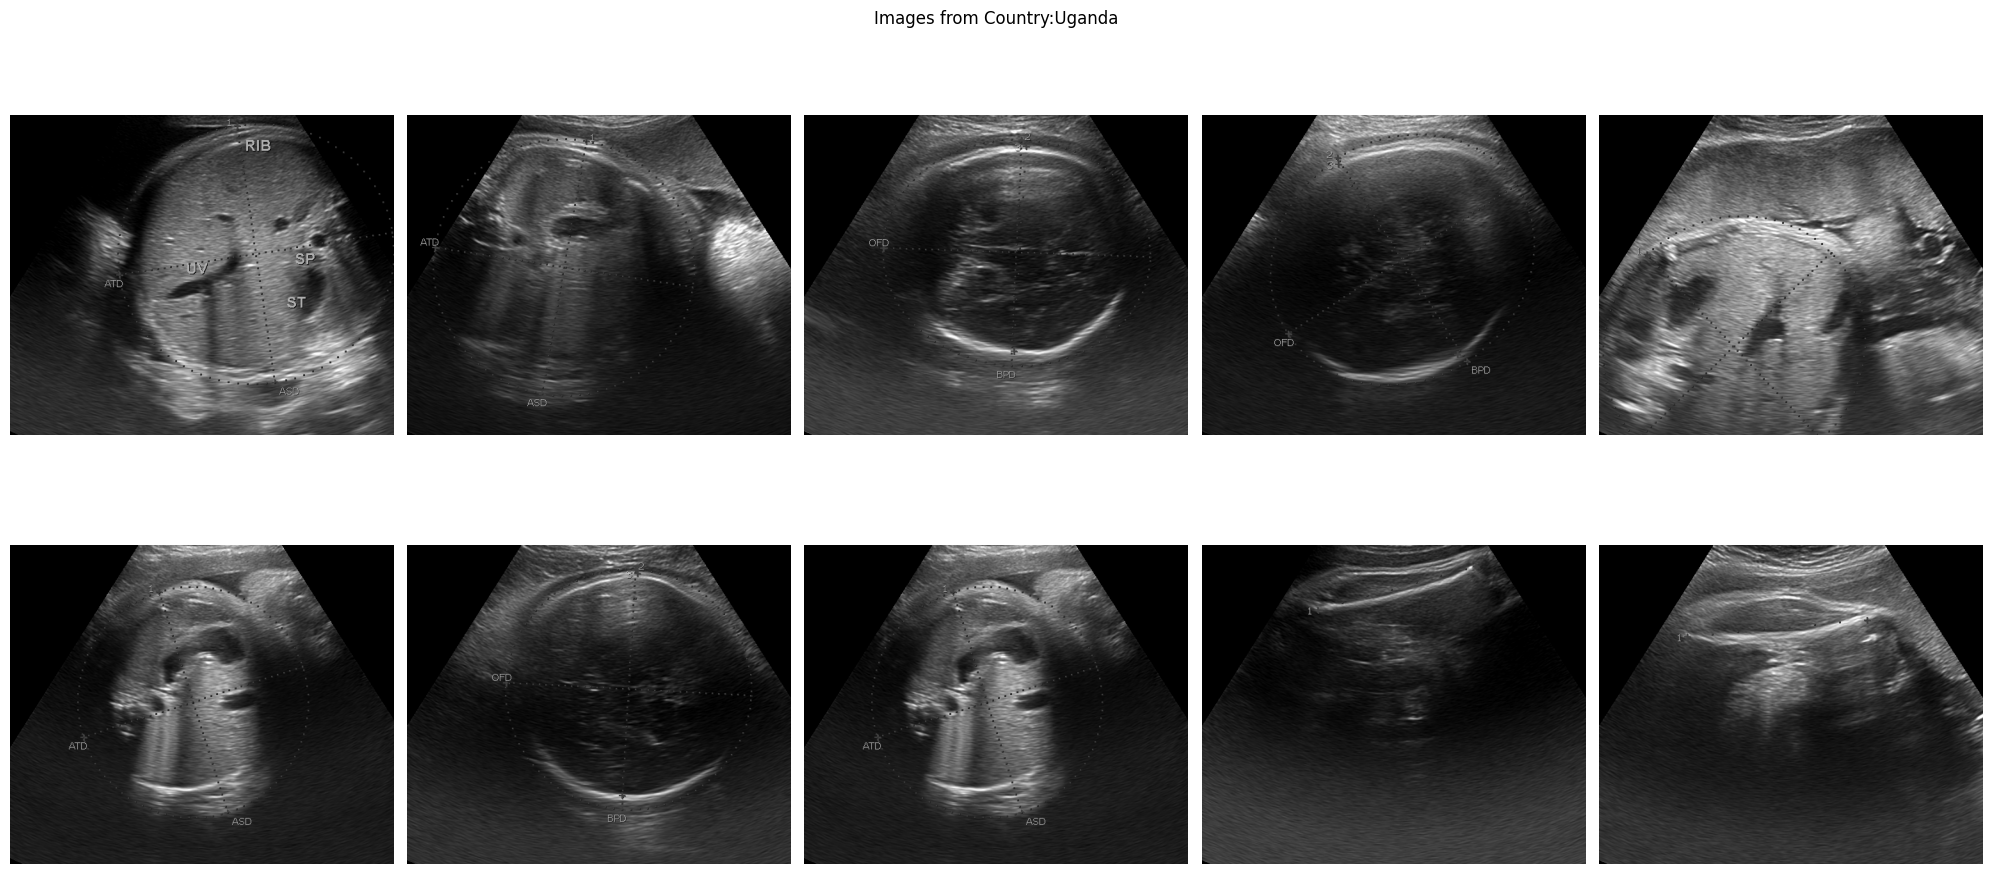

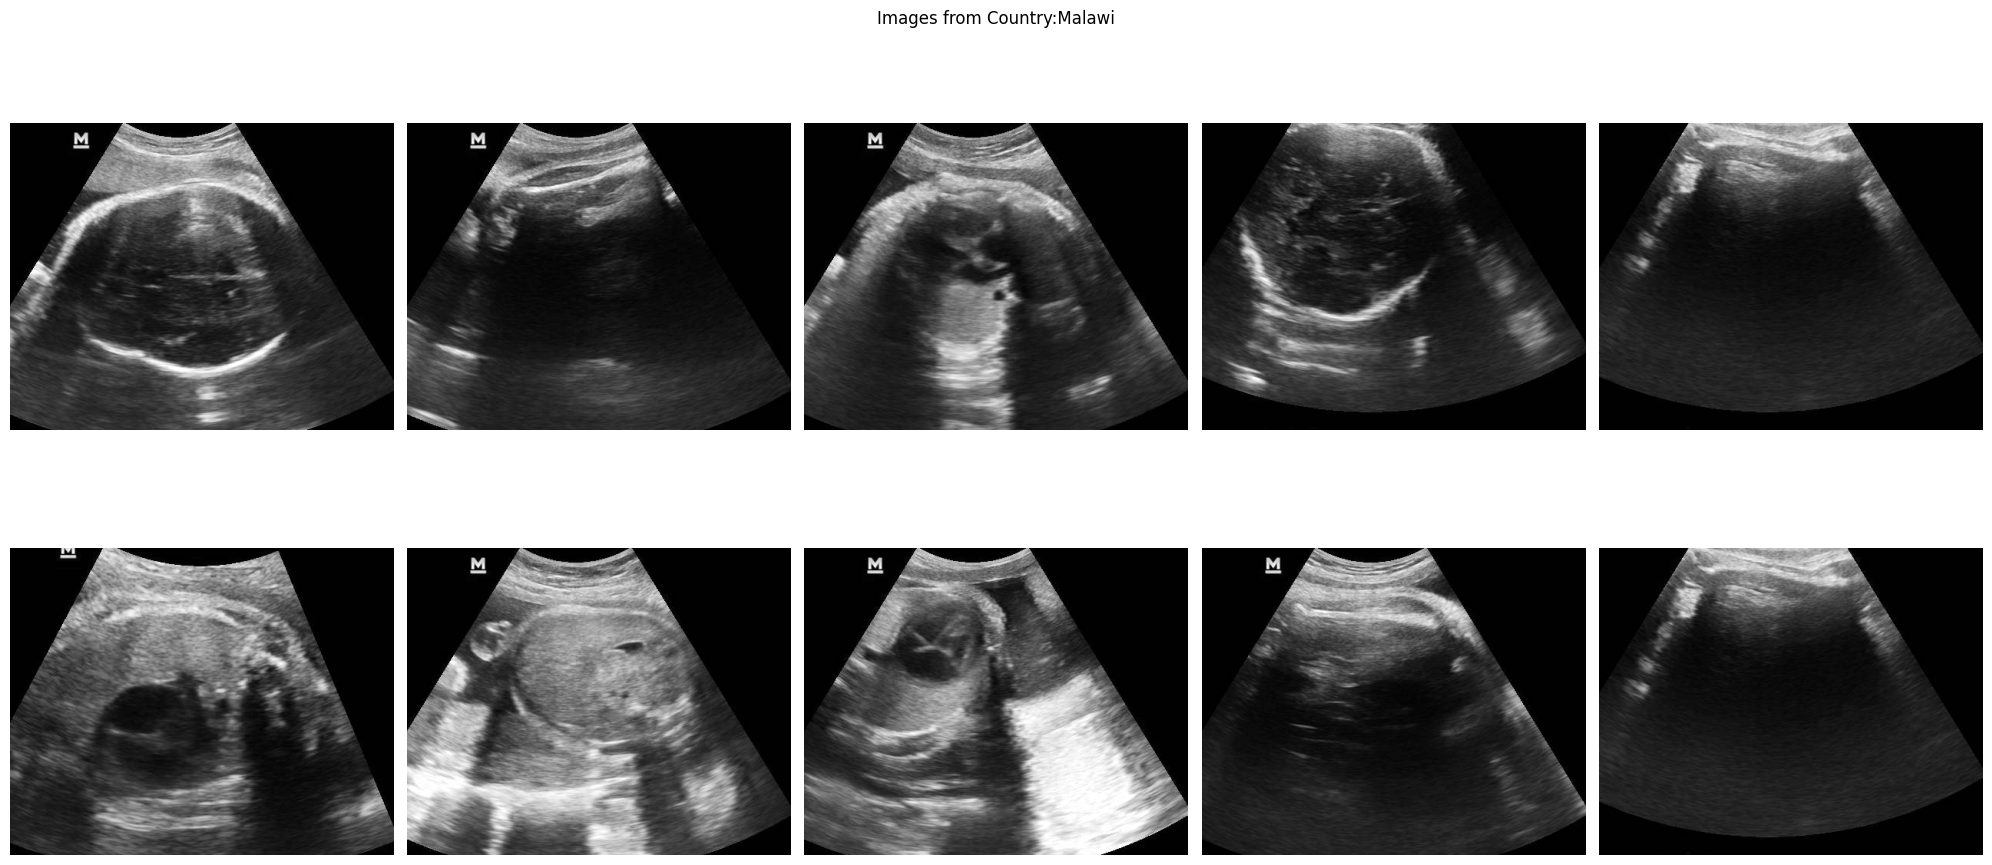

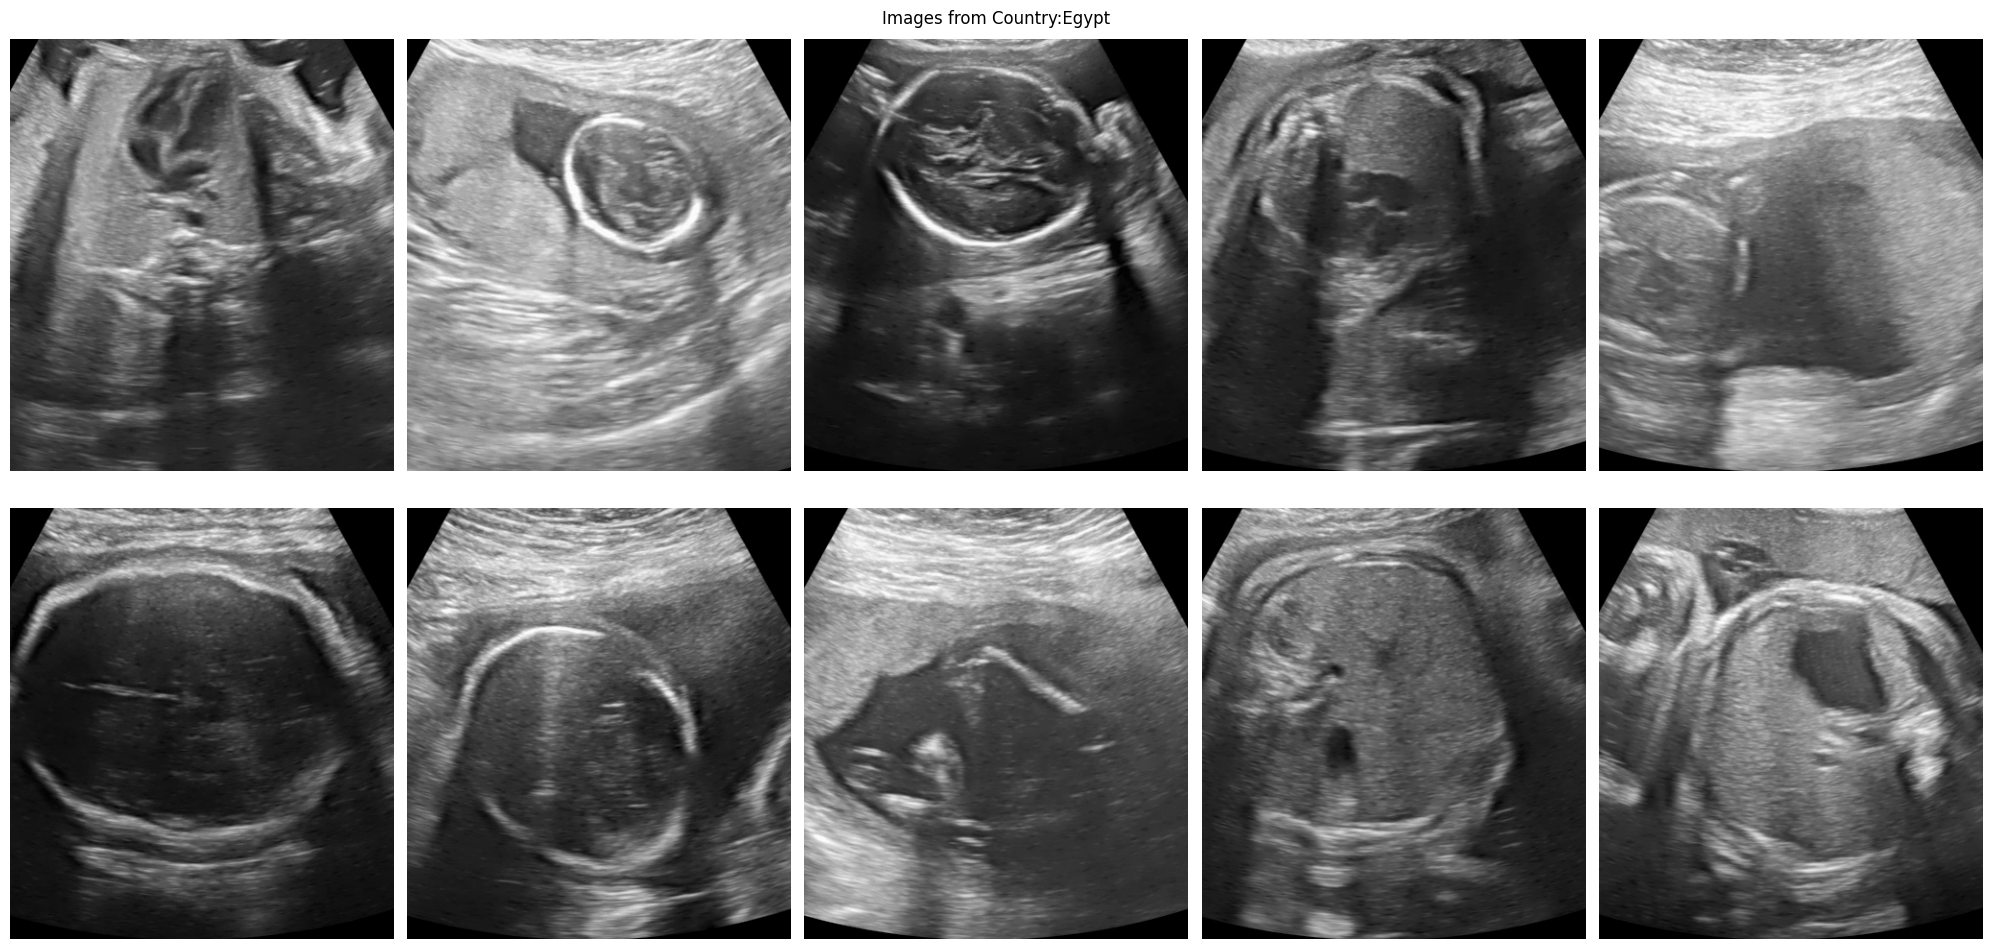

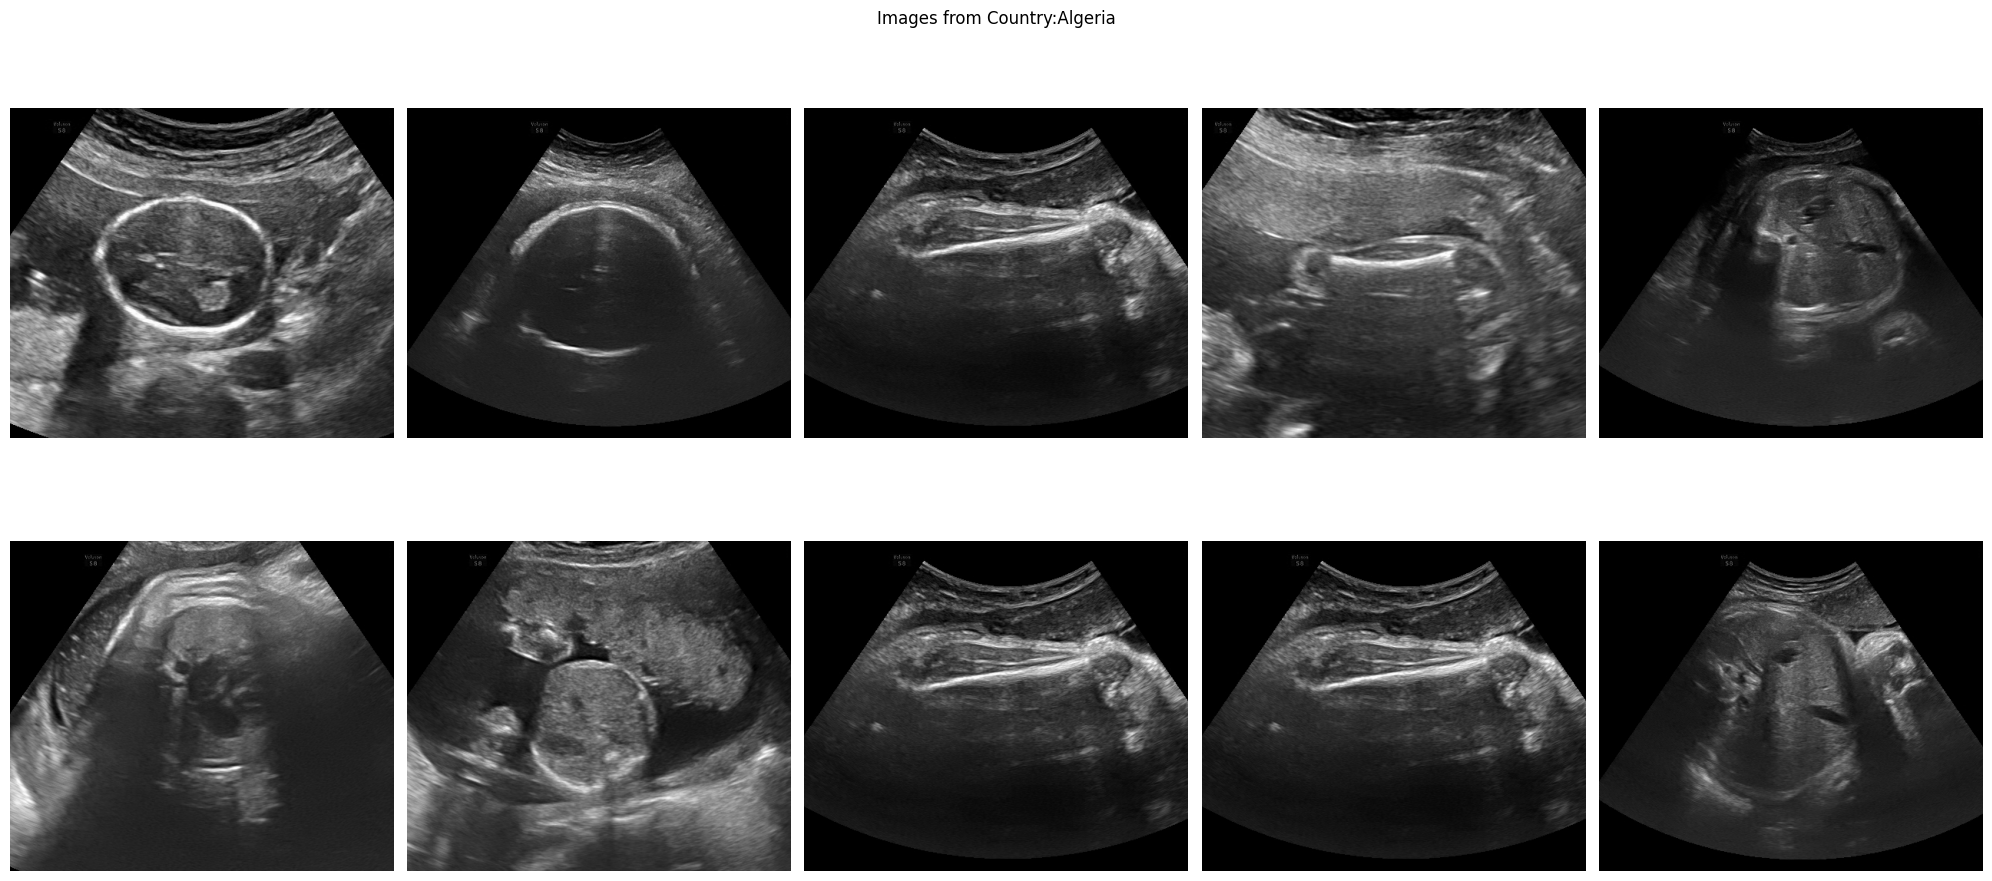

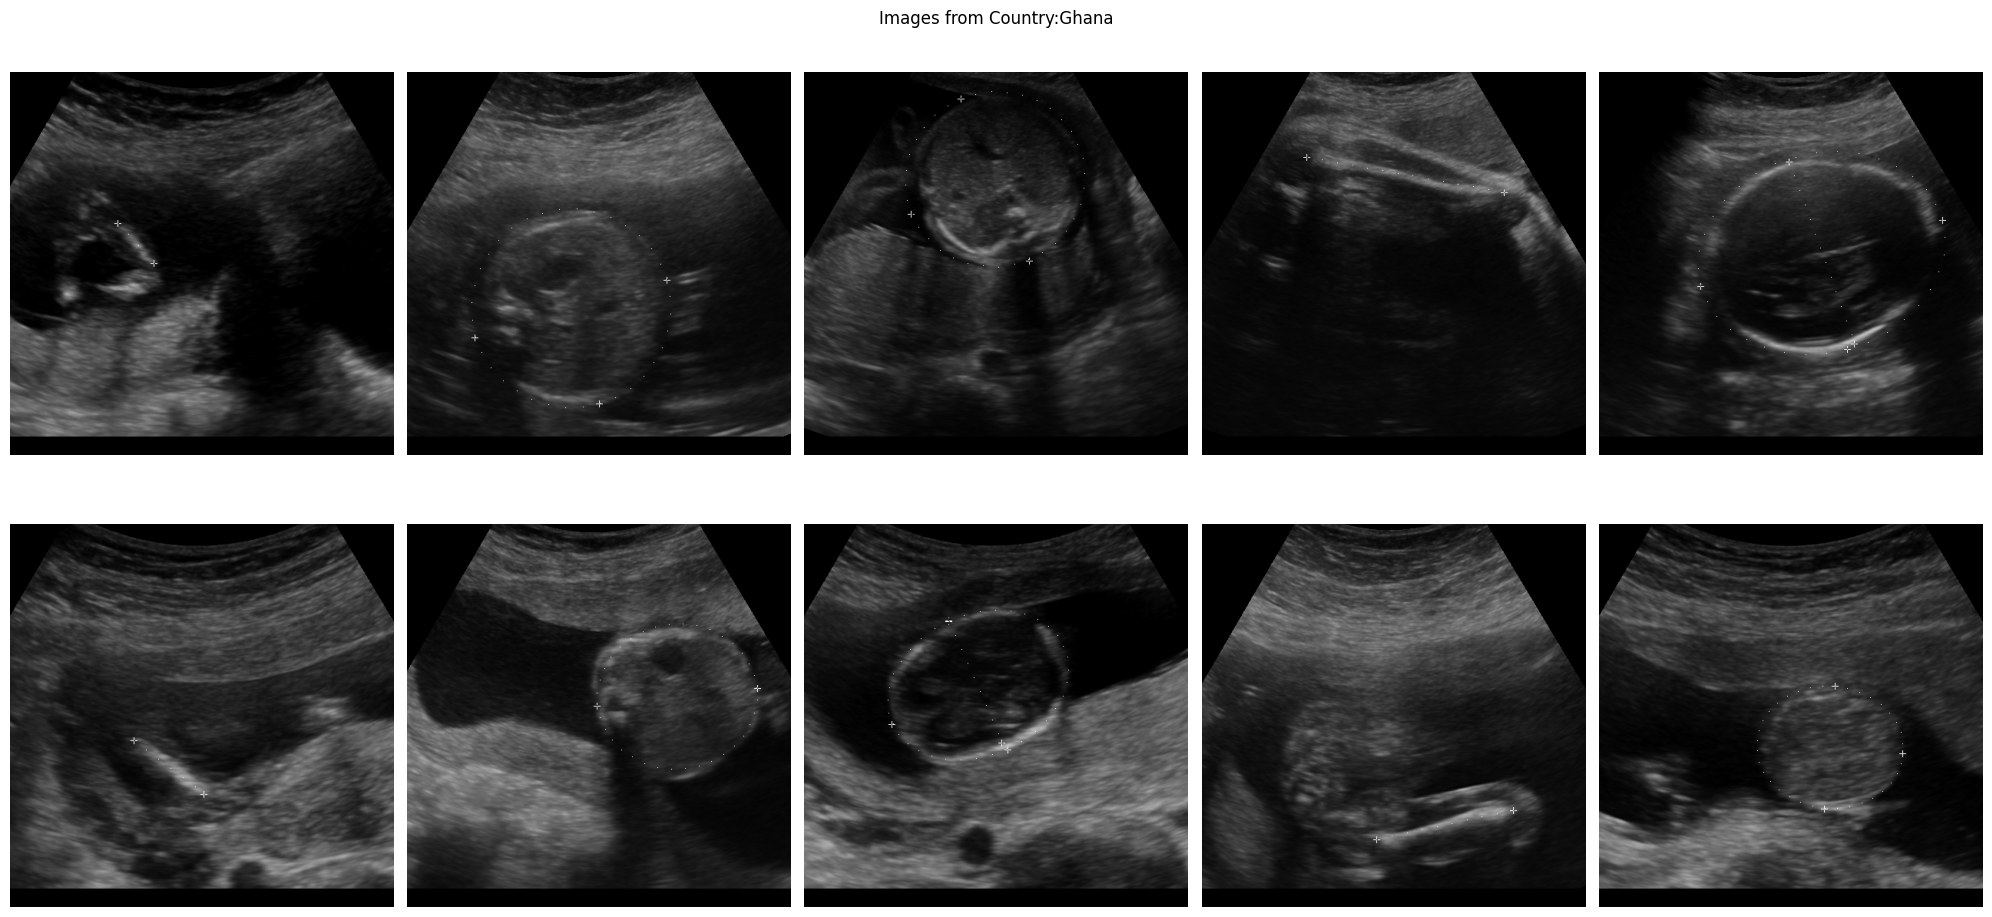

In [42]:
# Ten random images per country (raw, before curation)
african_root = Path(raw_paths["african_root"])
countries = sorted(d.name for d in african_root.iterdir() if d.is_dir())

for country in countries:
    country_path = african_root / country
    ten_imgs = random.choices(os.listdir(country_path), k=10)

    plt.figure(figsize=(20, 10))
    for idx, img in enumerate(ten_imgs):
        plt.subplot(2, 5, idx + 1)
        image = cv2.imread(str(country_path / img))
        plt.imshow(image)
        plt.grid(False)
        plt.axis("off")
    plt.tight_layout(pad=1)
    plt.suptitle(f"Images from country: {country}")

## 1.3 Curate the splits

- **African**: Malawi is held out entirely as the test set. The other four countries are
  pooled and split 70/30 into train/val at patient level (`random_state=42`).
- **Fetal DB**: the CSV's own `Train == 0` rows form the test set; the `Train == 1` rows are
  split 70/30 into train/val at patient level.
- Classes other than brain, femur and abdomen are mapped to `other`.

In [ ]:
# AFRICAN DATASET

stats_african = prepare_african(
    root=raw_paths["african_root"],
    csv_path=raw_paths["african_csv"],
    out_dir=AFRICAN_OUT,
)


In [ ]:
print("African dataset curated:")
for split, s in stats_african.items():
    print(f"  {split:5s}: {s['n_images']:5d} images | {s['class_counts']}")


In [ ]:
# FETAL DB DATASET

stats_fetal = prepare_fetal(
    root=raw_paths["fetal_root"],
    csv_path=raw_paths["fetal_csv"],
    out_dir=FETAL_OUT,
)


In [ ]:
print("\nFetal DB dataset curated:")
for split, s in stats_fetal.items():
    print(f"  {split:5s}: {s['n_images']:5d} images | {s['class_counts']}")
print("\nDatasets ready under data/african/ and data/fetal_db/")


In [ ]:
# Final sanity check: image counts per split and class
CLASSES_4C = ["abdomen", "brain", "femur", "other"]
print("African:")
get_split_stats(AFRICAN_OUT, CLASSES_4C)
print("\nFetal DB:")
get_split_stats(FETAL_OUT, CLASSES_4C)